# Predicción de impago de tarjetas de crédito, evaluación  final

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, brier_score_loss,
    confusion_matrix, roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

In [2]:
TRAIN_PATH = "credit_train.csv"
TEST_PATH = "credit_test.csv"
RANDOM_STATE = 42
CV_FOLDS = 5
TARGET = "default"
LOGISTIC_C = 10
FOREST_TREES = 300
FOREST_MAX_DEPTH = 12
FOREST_MIN_SAMPLES_LEAF = 20
CPU_CORES = 8
os.environ["LOKY_MAX_CPU_COUNT"] = str(CPU_CORES)

## 1. Introducción

En este notebook evaluamos el modelo elegido anteriormente, Random Forest, contra la regresión logística. Elige el umbral de decisión, comprueba la calibración, mide el rendimiento en el test y analiza qué variables pesan más. Termina con las conclusiones de todo el proyecto.


## 2. Carga de datos

In [3]:
credit_train = pd.read_csv(TRAIN_PATH)
credit_test = pd.read_csv(TEST_PATH)

categorical_features = ["SEX", "EDUCATION", "MARRIAGE", "STATUS_1"]
numeric_features = [
    "AGE", "AGE_SQUARED_DEVIATION", "LOG_LIMIT",
    "DELAY_1", "MONTHS_DELAYED", "WORST_DELAY", "MONTHS_PAID_FULL",
    "UTILIZATION_MEAN", "PAYMENT_RATIO_MEAN", "DEBT_TREND",
    "LOG_PAYMENT_LAST", "LOG_PAYMENT_MEAN", "INACTIVE",
]
model_features = categorical_features + numeric_features

X_train, y_train = credit_train[model_features], credit_train[TARGET]
X_test, y_test = credit_test[model_features], credit_test[TARGET]

pd.DataFrame({
    "clientes": [len(y_train), len(y_test)],
    "impagos": [y_train.sum(), y_test.sum()],
    "tasa_impago": [y_train.mean(), y_test.mean()],
}, index=["entrenamiento", "test"]).round(3)

,clientes,impagos,tasa_impago
entrenamiento,24000,5309,0.221
test,6000,1327,0.221


## 3. Modelos

Reconstruimos los dos modelos con los hiperparámetros elegidos en `02_Modelado_CC` y el mismo preprocesado.

In [4]:
forest_model = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("categorical", OneHotEncoder(), categorical_features),
        ("numeric", "passthrough", numeric_features),
    ])),
    ("classifier", RandomForestClassifier(
        n_estimators=FOREST_TREES,
        max_depth=FOREST_MAX_DEPTH,
        min_samples_leaf=FOREST_MIN_SAMPLES_LEAF,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    )),
])

logistic_model = Pipeline([
    ("preprocessor", ColumnTransformer([
        ("categorical", OneHotEncoder(drop="first"), categorical_features),
        ("numeric", StandardScaler(), numeric_features),
    ])),
    ("classifier", LogisticRegression(C=LOGISTIC_C, max_iter=1000)),
])

Calculamos las predicciones fuera de partición del conjunto de entrenamiento, que usaremos para elegir el umbral y comprobar la calibración, y después entrenamos los modelos con todo el conjunto.

In [5]:
cross_validation = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

reference_models = {"Regresión logística": logistic_model, "Random Forest": forest_model}
out_of_fold_probabilities = {}
for model_name, model in reference_models.items():
    probabilities = cross_val_predict(
        model, X_train, y_train, cv=cross_validation, method="predict_proba"
    )
    out_of_fold_probabilities[model_name] = probabilities[:, 1]
    model.fit(X_train, y_train)

La función `threshold_metrics` convierte las probabilidades en decisiones (1 = se marca como riesgo de impago) y resume la matriz de confusión, la precisión, el recall y el F1.

In [6]:
def threshold_metrics(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    true_negatives, false_positives, false_negatives, true_positives = confusion_matrix(
        y_true, predictions
    ).ravel()
    precision = true_positives / (true_positives + false_positives)
    recall = true_positives / (true_positives + false_negatives)
    return {
        "umbral": threshold,
        "% marcados": predictions.mean() * 100,
        "impagos detectados (VP)": true_positives,
        "impagos no detectados (FN)": false_negatives,
        "buenos marcados (FP)": false_positives,
        "precisión": precision,
        "recall": recall,
        "F1": 2 * precision * recall / (precision + recall),
    }

## 4. Umbral de decisión

Para convertir las probabilidades en decisiones necesitamos un umbral. Usamos el que **maximiza el F1** del Random Forest, el equilibrio entre precisión y recall.

Probamos umbrales entre 0,05 y 0,70 sobre las predicciones fuera de partición del entrenamiento, sin tocar el test.

In [7]:
forest_probabilities = out_of_fold_probabilities["Random Forest"]

thresholds = np.round(np.arange(0.05, 0.71, 0.01), 2)
f1_scores = [
    threshold_metrics(y_train, forest_probabilities, threshold)["F1"]
    for threshold in thresholds
]

f1_by_threshold = pd.Series(f1_scores, index=thresholds)
decision_threshold = f1_by_threshold.idxmax()
decision_threshold

0.3

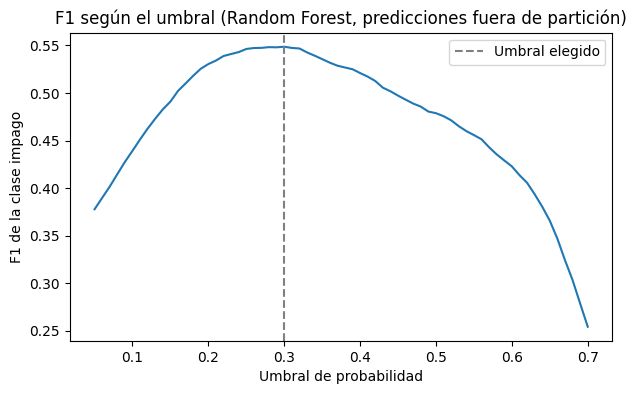

In [8]:
ax = f1_by_threshold.plot(figsize=(7, 4))
ax.axvline(decision_threshold, color="grey", linestyle="--", label="Umbral elegido")
ax.set_title("F1 según el umbral (Random Forest, predicciones fuera de partición)")
ax.set_xlabel("Umbral de probabilidad")
ax.set_ylabel("F1 de la clase impago")
ax.legend()
plt.show()

**El umbral que maximiza el F1 es 0,30**, muy por debajo del 0,5 por defecto. Con él, en entrenamiento, el Random Forest marca al 23 % de los clientes, detecta el 56 % de los impagos y acierta en el 54 % de los que marca (F1 de 0,549).

La curva es plana entre 0,25 y 0,35 (F1 de 0,536 a 0,549), así que pequeños cambios de umbral apenas importan. Con el 0,5 por defecto, el F1 bajaría a 0,48.

## 5. Calibración

Debemos asegurarnos de que las predicciones quue arroja el modelo son ciertas. Debemos agrupar las predicciones fuera de partición en varios tramos con el mismo número de clientes y comparando la probabilidad media predicha con la tasa real de impago.

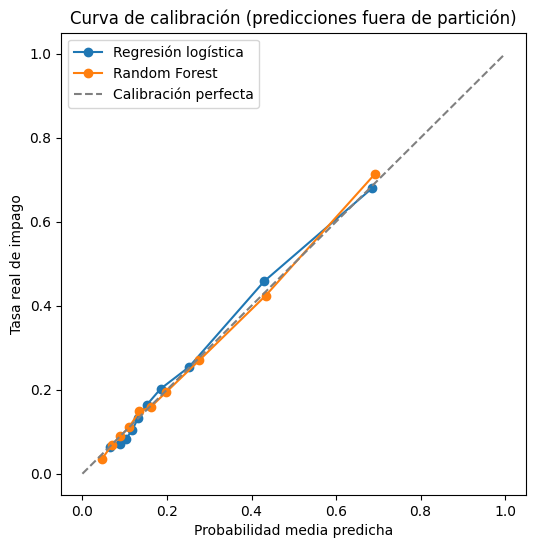

In [9]:
fig, ax = plt.subplots(figsize=(6, 6))
for model_name in ["Regresión logística", "Random Forest"]:
    observed_rate, predicted_probability = calibration_curve(
        y_train, out_of_fold_probabilities[model_name], n_bins=10, strategy="quantile"
    )
    ax.plot(predicted_probability, observed_rate, marker="o", label=model_name)
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Calibración perfecta")
ax.set_title("Curva de calibración (predicciones fuera de partición)")
ax.set_xlabel("Probabilidad media predicha")
ax.set_ylabel("Tasa real de impago")
ax.legend()
plt.show()

**Los dos modelos están bien calibrados**: los puntos siguen la diagonal, con desviaciones de 2 puntos como máximo. No hace falta corregirlos.

## 6. Evaluación final en el test

Usamos el test por primera y única vez, con el modelo y el umbral ya fijados. La logística se incluye como referencia.

In [10]:
test_probabilities = {
    "Regresión logística": logistic_model.predict_proba(X_test)[:, 1],
    "Random Forest": forest_model.predict_proba(X_test)[:, 1],
}

test_metrics = pd.DataFrame({
    model_name: {
        "ROC-AUC": roc_auc_score(y_test, probabilities),
        "PR-AUC": average_precision_score(y_test, probabilities),
        "Brier score": brier_score_loss(y_test, probabilities),
    }
    for model_name, probabilities in test_probabilities.items()
}).T
test_metrics.round(4)

,ROC-AUC,PR-AUC,Brier score
Regresión logística,0.7638,0.5255,0.1390
Random Forest,0.7793,0.5644,0.1347


In [11]:
test_decisions = pd.DataFrame({
    model_name: threshold_metrics(y_test, probabilities, decision_threshold)
    for model_name, probabilities in test_probabilities.items()
}).T
test_decisions.round(3)

,umbral,% marcados,impagos detectados (VP),impagos no detectados (FN),buenos marcados (FP),precisión,recall,F1
Regresión logística,0.3,20.517,672.0,655.0,559.0,0.546,0.506,0.525
Random Forest,0.3,22.667,731.0,596.0,629.0,0.538,0.551,0.544


La matriz de confusión del Random Forest muestra los cuatro tipos de decisión en el test: impagos detectados, impagos que se escapan, buenos clientes marcados por error y buenos clientes aprobados.

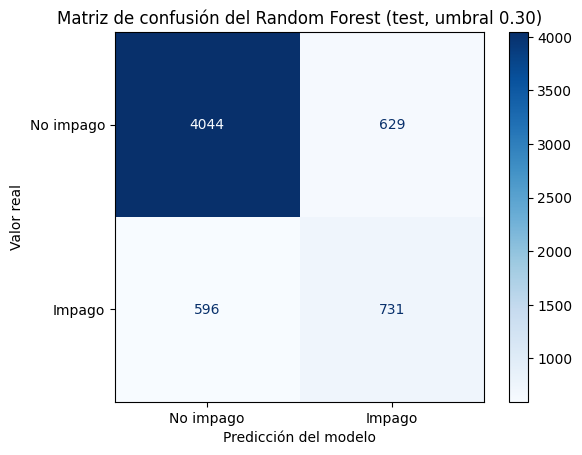

In [12]:
test_flagged = (test_probabilities["Random Forest"] >= decision_threshold).astype(int)
display = ConfusionMatrixDisplay.from_predictions(
    y_test, test_flagged, display_labels=["No impago", "Impago"],
    cmap="Blues", values_format="d",
)
display.ax_.set_title(f"Matriz de confusión del Random Forest (test, umbral {decision_threshold:.2f})")
display.ax_.set_xlabel("Predicción del modelo")
display.ax_.set_ylabel("Valor real")
plt.show()

**El test confirma la validación cruzada**, sin señales de sobreajuste:

| Modelo | ROC-AUC | PR-AUC | Brier score |
|---|---|---|---|
| Regresión logística | 0,764 | 0,526 | 0,139 |
| Random Forest | 0,779 | 0,564 | 0,135 |

De los 6.000 clientes del test y con el umbral de 0,30, el Random Forest:

- detecta **731 de los 1.327 impagos (55 %)** y deja escapar 596;
- marca por error a **629 de los 4.673 clientes buenos (13 %)**;
- de cada 100 clientes marcados, 54 impagan de verdad.

Frente a la logística, detecta 59 impagos más a cambio de marcar a 70 clientes buenos más (F1 de 0,544 frente a 0,525).

En un caso real, podríamos ajustar el umbral para ajustarlo segúuun los costes. ¿Que es más costoso? ¿Un falso positivo o un falso negativo? Se podría bajar el umbral para detectar más impagos a cambio de más rechazos.

## 7. Interpretabilidad: importancia por permutación

Para cada variable desordenamos sus valores en el test y medimos cuánto cae la PR-AUC del Random Forest. Cuanto más cae, más depende el modelo de esa variable. Se calcula sobre las 17 variables originales, no sobre las columnas one-hot.

In [13]:
permutation_result = permutation_importance(
    forest_model, X_test, y_test, scoring="average_precision",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1,
)
feature_importance = pd.Series(
    permutation_result.importances_mean, index=model_features
).sort_values()

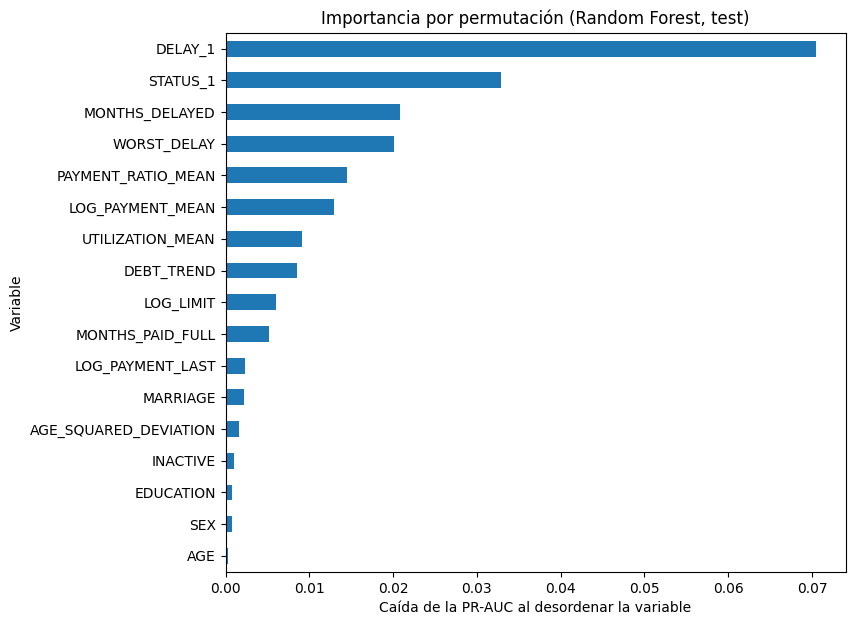

In [14]:
ax = feature_importance.plot(kind="barh", figsize=(8, 7))
ax.set_title("Importancia por permutación (Random Forest, test)")
ax.set_xlabel("Caída de la PR-AUC al desordenar la variable")
ax.set_ylabel("Variable")
plt.show()

**El comportamiento de pago reciente es lo que mejor predice el impago.**

1. **Retraso y estado de pago en septiembre** (`DELAY_1` y `STATUS_1`): la señal más fuerte.
2. **Historial de retrasos** (`MONTHS_DELAYED` y `WORST_DELAY`), seguido de la capacidad de pago y el uso del crédito.
3. **Variables demográficas: casi irrelevantes**, con una importancia de 0,002 o menos.

Son importancias predictivas, no efectos causales.

El mapa de calor muestra la tasa real de impago en el conjunto de entrenamiento según dos de las variables más importantes: los meses de retraso en septiembre (`DELAY_1`, agrupando 3 o más) y el número de meses con retraso en el semestre (`MONTHS_DELAYED`).

In [15]:
delay_data = credit_train.assign(DELAY_1=credit_train["DELAY_1"].clip(upper=3))
default_rate_grid = delay_data.pivot_table(
    index="DELAY_1", columns="MONTHS_DELAYED", values=TARGET, aggfunc="mean"
).rename(index={3: "3 o más"})

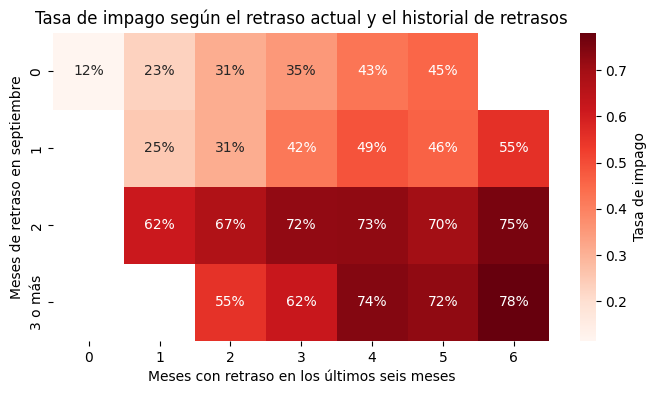

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.heatmap(
    default_rate_grid, annot=True, fmt=".0%", cmap="Reds", ax=ax,
    cbar_kws={"label": "Tasa de impago"},
)
ax.set_title("Tasa de impago según el retraso actual y el historial de retrasos")
ax.set_xlabel("Meses con retraso en los últimos seis meses")
ax.set_ylabel("Meses de retraso en septiembre")
plt.show()

- **Sin retraso en septiembre**, el riesgo crece con el historial: del 12 % sin ningún retraso al 45 % con cinco meses de retraso.
- **Con 2 o más meses de retraso en septiembre**, el impago supera el 55 % en casi todos los casos y llega al 78 % con un historial de retrasos constante.
- **Un mes de retraso en septiembre (código 1) pesa mucho menos que dos:** 25 % frente a 62 % con el mismo historial. Encaja con lo visto en el EDA: el código 1 es poco fiable.

Las dos variables se complementan: el retraso actual marca el salto de riesgo y el historial lo gradúa. Es el tipo de interacción que los árboles captan mejor que la logística.

## 8. Conclusiones

### 8.1 ¿Cómo varía el impago según las variables demográficas?

| Variable | Más impago | Menos impago | V de Cramér |
|---|---|---|---|
| Límite de crédito | ≤ 50.000 NT$ (31,8 %) | > 500.000 NT$ (11,2 %) | 0,164 |
| Educación | Bachillerato (25,2 %) | Posgrado (19,2 %) | 0,073 |
| Edad | 21–25 y > 60 años (≈ 27 %) | 31–35 años (19,4 %) | 0,062 |
| Sexo | Hombres (24,2 %) | Mujeres (20,8 %) | 0,040 |
| Estado civil | Divorciados (26,0 %) | Solteros (20,9 %) | 0,034 |

Las diferencias son estadísticamente significativas, pero pequeñas, y casi desaparecen cuando el modelo tiene en cuenta el comportamiento de pago.

NOTA: El coeficiente V de Cramér es una medida estadística que evalúa la fuerza de asociación entre dos variables nominales toma valores entre 0 (independencia) y 1 (dependencia)

### 8.2 ¿Qué variables predicen mejor el impago?

Aunque parezca predecir una obviedad, el comportamiento de pago reciente es la variable con mayor peso. El retraso en septiembre, seguido del historial de retrasos y de la capacidad de pago son las variables de mayor peso. Sin embargo cabe destacar, como hemos respondido antes, que las variables demográficas son casi irrelevantes. De esto último se puede sacar información importante.

### 8.3 Modelo final

| Modelo | ROC-AUC test | PR-AUC test | Brier test |
|---|---|---|---|
| Regresión logística | 0,764 | 0,526 | 0,139 |
| Random Forest | **0,779** | **0,564** | **0,135** |

- **Random Forest** es el modelo elegido: mejor en todas las métricas y bien calibrado, aunque su ventaja sobre la logística es moderada.
- Con el **umbral de 0,30** (F1 máximo), en el test detecta el **55 % de los impagos** y solo marca por error al **13 % de los clientes buenos**. En un caso real, el umbral se ajustaría con los costes reales del banco.
